###Librerías

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


###Dataset

In [6]:
df_movies=pd.read_csv("../CSV/netflix_movies_detailed_up_to_2025.csv")
print(df_movies.head(5))

df_tv=pd.read_csv("../CSV/netflix_tv_shows_detailed_up_to_2025.csv")
print(df_tv.head(5))


   show_id   type                                         title  \
0    10192  Movie                           Shrek Forever After   
1    27205  Movie                                     Inception   
2    12444  Movie  Harry Potter and the Deathly Hallows: Part 1   
3    38757  Movie                                       Tangled   
4    10191  Movie                      How to Train Your Dragon   

                      director  \
0                Mike Mitchell   
1            Christopher Nolan   
2                  David Yates   
3   Byron Howard, Nathan Greno   
4  Chris Sanders, Dean DeBlois   

                                                cast  \
0  Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...   
1  Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...   
2  Daniel Radcliffe, Emma Watson, Rupert Grint, T...   
3  Mandy Moore, Zachary Levi, Donna Murphy, Ron P...   
4  Jay Baruchel, Gerard Butler, Craig Ferguson, A...   

                                    country  date_added

In [7]:
# Ficha técnica requerida
print("=== FICHA TÉCNICA DE DATASETS ===")
print(f"Películas: {df_movies.shape[0]} filas | {df_movies.shape[1]} columnas")
print(f"Series:    {df_tv.shape[0]} filas | {df_tv.shape[1]} columnas\n")


=== FICHA TÉCNICA DE DATASETS ===
Películas: 16000 filas | 18 columnas
Series:    16000 filas | 16 columnas



In [8]:
# Integración: Se etiquetan por 'type' y se vinculan por 'show_id'
df_movies['type'] = 'Movie'
df_tv['type'] = 'TV Show'


###Limpieza

In [9]:
# Contar y aislar duplicados por show_id
dup_movies = df_movies[df_movies.duplicated(subset=['show_id'], keep=False)]
dup_tv = df_tv[df_tv.duplicated(subset=['show_id'], keep=False)]

print(f"Registros duplicados encontrados en Películas: {len(dup_movies)}")
print(f"Registros duplicados encontrados en Series: {len(dup_tv)}")

if len(dup_tv) > 0:
    print("\n--- EVIDENCIA DE REGISTROS DUPLICADOS HALLADOS EN SERIES ---")
    print(dup_tv[['show_id', 'title', 'release_year', 'popularity']].sort_values('show_id').head(6))


Registros duplicados encontrados en Películas: 0
Registros duplicados encontrados en Series: 18

--- EVIDENCIA DE REGISTROS DUPLICADOS HALLADOS EN SERIES ---
       show_id                                     title  release_year  \
15540   252630  Joe Lycett’s United States of Birmingham          2025   
15539   252630  Joe Lycett’s United States of Birmingham          2025   
15358   278867                                  Ensemble          2025   
15360   278867                                  Ensemble          2025   
15398   279457                            Ghassan & Mina          2025   
15400   279457                            Ghassan & Mina          2025   

       popularity  
15540      11.531  
15539      11.550  
15358      11.044  
15360      18.407  
15398       9.631  
15400      16.051  


In [10]:
# Ejecución del depurado de duplicados
df_movies_clean = df_movies.drop_duplicates(subset=['show_id'], keep='first').copy()
df_tv_clean = df_tv.drop_duplicates(subset=['show_id'], keep='first').copy()

print(f"\n Series tras remover duplicados: {len(df_tv_clean)} registros únicos.")



 Series tras remover duplicados: 15991 registros únicos.


**Justificación de limpieza:** en Series hay 9 registros duplicados por `show_id` que corresponden a la misma producción registrada con ligeras variaciones en métricas temporales (como `popularity`). Para mantener la regla de negocio de "un único registro por contenido", se remueve la segunda instancia de cada caso, conservando la primera. A partir de aquí, **todo el análisis y los gráficos del notebook se construyen sobre `df_movies_clean` / `df_tv_clean`**, nunca sobre los dataframes originales.

In [11]:
# Inspeccionar valores faltantes (sobre el dataset YA depurado de duplicados)
print("--- VALORES FALTANTES DETECTADOS EN PELÍCULAS ---")
print(df_movies_clean.isnull().sum()[df_movies_clean.isnull().sum() > 0])

print("\n--- VALORES FALTANTES DETECTADOS EN SERIES ---")
print(df_tv_clean.isnull().sum()[df_tv_clean.isnull().sum() > 0])


--- VALORES FALTANTES DETECTADOS EN PELÍCULAS ---
director         132
cast             204
country          466
duration       16000
genres           107
description      132
dtype: int64

--- VALORES FALTANTES DETECTADOS EN SERIES ---
director       10960
cast            1156
country         1795
genres           972
description     3203
dtype: int64


**Hallazgos y justificación de limpieza — nulos:** las variables cualitativas (`director`, `cast`, `country`, `genres`) presentan nulos en ambos datasets; el caso más relevante es `director` en Series (10.960 nulos, 68,5% de los registros, medido **después** de remover los duplicados). Eliminar esas filas descartaría gran parte de la muestra, por lo que se imputan los faltantes con "Sin Información" (o "Sin Género" en `genres`), preservando el 100% de los registros. La variable `duration` en películas presenta 16.000 valores nulos (100% ausente): al estar totalmente vacía, no se imputa, se documenta como **no utilizable**.

In [12]:
# Ejecución de la imputación de nulos cualitativos
columnas_texto = ['director', 'cast', 'country', 'genres']

for col in columnas_texto:
    df_movies_clean[col] = df_movies_clean[col].fillna('Sin Información' if col != 'genres' else 'Sin Género')
    df_tv_clean[col] = df_tv_clean[col].fillna('Sin Información' if col != 'genres' else 'Sin Género')

print(" Imputación completada: se mantuvieron todos los registros sin pérdida de datos.")


 Imputación completada: se mantuvieron todos los registros sin pérdida de datos.


###Formatos

In [13]:
print(f"Tipo de dato actual de 'date_added' en Películas: {df_movies_clean['date_added'].dtype}")


Tipo de dato actual de 'date_added' en Películas: str


In [14]:
# Convertir a Datetime y extraer variables temporales de análisis
df_movies_clean['date_added_dt'] = pd.to_datetime(df_movies_clean['date_added'], errors='coerce')
df_movies_clean['year_added'] = df_movies_clean['date_added_dt'].dt.year

df_tv_clean['date_added_dt'] = pd.to_datetime(df_tv_clean['date_added'], errors='coerce')
df_tv_clean['year_added'] = df_tv_clean['date_added_dt'].dt.year

print(" Fechas convertidas exitosamente a Datetime.")


 Fechas convertidas exitosamente a Datetime.


In [15]:
print("Muestra de datos en 'duration' (Series):")
print(df_tv_clean['duration'].head(4))


Muestra de datos en 'duration' (Series):
0    1 Seasons
1    1 Seasons
2    1 Seasons
3    1 Seasons
Name: duration, dtype: str


In [16]:
# Extracción de la parte numérica con expresión regular
df_tv_clean['seasons_count'] = (
    df_tv_clean['duration']
    .astype(str)
    .str.extract(r'(\d+)')
    .astype('Int64')
)

print("\n Visualización del resultado tras la extracción:")
print(df_tv_clean[['title', 'duration', 'seasons_count']].head(3))



 Visualización del resultado tras la extracción:
               title   duration  seasons_count
0        Running Man  1 Seasons              1
1              Conan  1 Seasons              1
2  MasterChef Greece  1 Seasons              1


In [17]:
# CORRECCIÓN: no basta con mirar head() -- se valida la variable completa antes de darla por buena.
print("Distribución completa de 'duration' en Series:")
print(df_tv_clean['duration'].value_counts())

print("\nDistribución completa de 'seasons_count':")
print(df_tv_clean['seasons_count'].value_counts())

print(f"\nValores únicos de seasons_count: {df_tv_clean['seasons_count'].nunique()}")


Distribución completa de 'duration' en Series:
duration
1 Seasons    15991
Name: count, dtype: int64

Distribución completa de 'seasons_count':
seasons_count
1    15991
Name: count, dtype: Int64

Valores únicos de seasons_count: 1


In [18]:
print("Muestra de géneros agrupados:")
print(df_movies_clean['genres'].head(3))


Muestra de géneros agrupados:
0    Comedy, Adventure, Fantasy, Animation, Family
1               Action, Science Fiction, Adventure
2                               Adventure, Fantasy
Name: genres, dtype: str


In [19]:
# Función para desanidar columnas multivalor
def desanidar_variable(df, columna):
    df_temp = df.copy()
    df_temp[columna] = df_temp[columna].astype(str).str.split(', ')
    return df_temp.explode(columna)

# Crear subconjunto desanidado de géneros (sobre datos limpios)
df_movies_genres_exploded = desanidar_variable(df_movies_clean, 'genres')

print("--- TOP 5 GÉNEROS INDIVIDUALES EN PELÍCULAS (excluyendo 'Sin Género') ---")
top_genres_movies = df_movies_genres_exploded[df_movies_genres_exploded['genres'] != 'Sin Género']['genres'].value_counts()
print(top_genres_movies.head(5))


--- TOP 5 GÉNEROS INDIVIDUALES EN PELÍCULAS (excluyendo 'Sin Género') ---
genres
Drama       6910
Comedy      4533
Thriller    3769
Action      3239
Romance     2571
Name: count, dtype: int64


In [20]:
# Función para desanidar la variable multivalor 'country'
def desanidar_pais(df, columna):
    df_temp = df.copy()
    df_temp[columna] = df_temp[columna].astype(str).str.split(', ')
    return df_temp.explode(columna)

# Crear DataFrames con países separados por fila (sobre datos limpios)
df_movies_country_exploded = desanidar_pais(df_movies_clean, 'country')
df_tv_country_exploded = desanidar_pais(df_tv_clean, 'country')

print("--- TOP 5 PAÍSES DE PRODUCCIÓN EN PELÍCULAS (excluyendo 'Sin Información') ---")
top_countries_movies = df_movies_country_exploded[df_movies_country_exploded['country'] != 'Sin Información']['country'].value_counts()
print(top_countries_movies.head(5))


--- TOP 5 PAÍSES DE PRODUCCIÓN EN PELÍCULAS (excluyendo 'Sin Información') ---
country
United States of America    7762
United Kingdom              1743
France                      1701
Canada                      1063
Japan                        990
Name: count, dtype: int64


Nota: al desanidar genres y country se excluye la categoría de relleno ("Sin Género" / "Sin Información") solo del ranking Top-N, para no distorsionar cuál es el género o país más frecuente. Esto es distinto a eliminar filas: los registros originales con esos valores de relleno siguen presentes en df_movies_clean / df_tv_clean y en cualquier conteo general del catálogo.

###Valores atípicos

In [21]:
# Selección de columnas numéricas clave a auditar
columnas_num_movies = ['release_year', 'popularity', 'vote_count', 'vote_average', 'budget', 'revenue']
columnas_num_tv = ['release_year', 'popularity', 'vote_count', 'vote_average']

print("--- RESUMEN ESTADÍSTICO DE PELÍCULAS ---")
print(df_movies_clean[columnas_num_movies].describe().T[['min', '25%', '50%', '75%', 'max']])

print("\n--- RESUMEN ESTADÍSTICO DE SERIES ---")
print(df_tv_clean[columnas_num_tv].describe().T[['min', '25%', '50%', '75%', 'max']])


--- RESUMEN ESTADÍSTICO DE PELÍCULAS ---
                  min         25%        50%           75%           max
release_year  2010.00  2013.75000  2017.5000  2.021250e+03  2.025000e+03
popularity       3.86     7.84075    10.9135  1.733650e+01  3.876006e+03
vote_count       0.00    53.00000   138.0000  4.220000e+02  3.711900e+04
vote_average     0.00     5.60000     6.3000  6.923000e+00  1.000000e+01
budget           0.00     0.00000     0.0000  2.200000e+06  4.600000e+08
revenue          0.00     0.00000     0.0000  1.654473e+06  2.799439e+09

--- RESUMEN ESTADÍSTICO DE SERIES ---
                   min       25%     50%       75%        max
release_year  2010.000  2013.000  2017.0  2021.000   2025.000
popularity       2.323    24.898    36.2    62.217   6421.923
vote_count       0.000     1.000     4.0    30.000  24664.000
vote_average     0.000     2.800     6.8     7.800     10.000


###Filtro de anomalías financieras

In [22]:
# Revisar la distribución de valores en presupuesto y recaudación
print("Resumen de presupuesto en películas:")
print(df_movies_clean['budget'].describe())

# Contar exactamente cuántos ceros existen
ceros_budget = (df_movies_clean['budget'] == 0).sum()
ceros_revenue = (df_movies_clean['revenue'] == 0).sum()

print(f"\nPelículas con presupuesto en $0: {ceros_budget}")
print(f"Películas con recaudación en $0: {ceros_revenue}")


Resumen de presupuesto en películas:
count    1.600000e+04
mean     8.766792e+06
std      2.912450e+07
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      2.200000e+06
max      4.600000e+08
Name: budget, dtype: float64

Películas con presupuesto en $0: 11153
Películas con recaudación en $0: 10355


**Justificación de limpieza:** la gran mayoría de las películas registra 0 en `budget` (11.153) y `revenue` (10.355). Un presupuesto de cero no refleja un costo real sino la ausencia de un dato operativo. Calcular el indicador financiero ROI (`revenue / budget`) con ceros ocasionaría divisiones por cero indeterminadas. Por lo tanto, se aísla en un subconjunto solo aquellas producciones con valores estrictamente positivos (> 0) en ambas variables.

In [23]:
# Filtrar registros financieramente válidos y calcular ROI
# (ÚNICO criterio de ROI usado en todo el notebook: budget>0 AND revenue>0, roi = revenue/budget)
df_movies_financial = df_movies_clean[
    (df_movies_clean['budget'] > 0) & (df_movies_clean['revenue'] > 0)
].copy()

df_movies_financial['roi'] = df_movies_financial['revenue'] / df_movies_financial['budget']

print(f" Muestra financiera válida aislada: {len(df_movies_financial)} películas "
      f"({len(df_movies_financial)/len(df_movies_clean)*100:.1f}% del catálogo de películas).")
print(f"ROI promedio de la muestra: {df_movies_financial['roi'].mean():.2f}x")
print(f"ROI mediana de la muestra:  {df_movies_financial['roi'].median():.2f}x")


 Muestra financiera válida aislada: 3540 películas (22.1% del catálogo de películas).
ROI promedio de la muestra: 781.55x
ROI mediana de la muestra:  1.70x


In [24]:
# CORRECCIÓN: el promedio de ROI está fuertemente distorsionado por presupuestos irreales (ej. budget=$1).
# Se audita explícitamente antes de decidir qué estadístico reportar.
print("Top 5 ROI más altos (para auditar outliers):")
print(df_movies_financial.nlargest(5, 'roi')[['title', 'budget', 'revenue', 'roi']])

presupuestos_irrisorios = (df_movies_financial['budget'] < 1000).sum()
print(f"\nPelículas con budget < $1.000 (probable error de carga de datos, no presupuesto real): "
      f"{presupuestos_irrisorios}")

df_movies_financial_robusto = df_movies_financial[df_movies_financial['budget'] >= 1000].copy()
print(f"\nROI promedio EXCLUYENDO presupuestos < $1.000: "
      f"{df_movies_financial_robusto['roi'].mean():.2f}x  (n={len(df_movies_financial_robusto)})")
print(f"ROI mediana EXCLUYENDO presupuestos < $1.000:  "
      f"{df_movies_financial_robusto['roi'].median():.2f}x")


Top 5 ROI más altos (para auditar outliers):
                                                   title  budget   revenue  \
6269   The Beatles: Eight Days a Week - The Touring Y...       5  12283800   
13648                        No Dogs or Italians Allowed       5   1395922   
13935                                           Scrapper      84   1234483   
12594                                  The Good Neighbor     105     94909   
8803                                        Animal World  125000  69885700   

                roi  
6269   2.456760e+06  
13648  2.791844e+05  
13935  1.469623e+04  
12594  9.038952e+02  
8803   5.590856e+02  

Películas con budget < $1.000 (probable error de carga de datos, no presupuesto real): 10

ROI promedio EXCLUYENDO presupuestos < $1.000: 4.28x  (n=3530)
ROI mediana EXCLUYENDO presupuestos < $1.000:  1.70x


# Gráficos (construidos sobre los datos limpios: df_movies_clean / df_tv_clean)

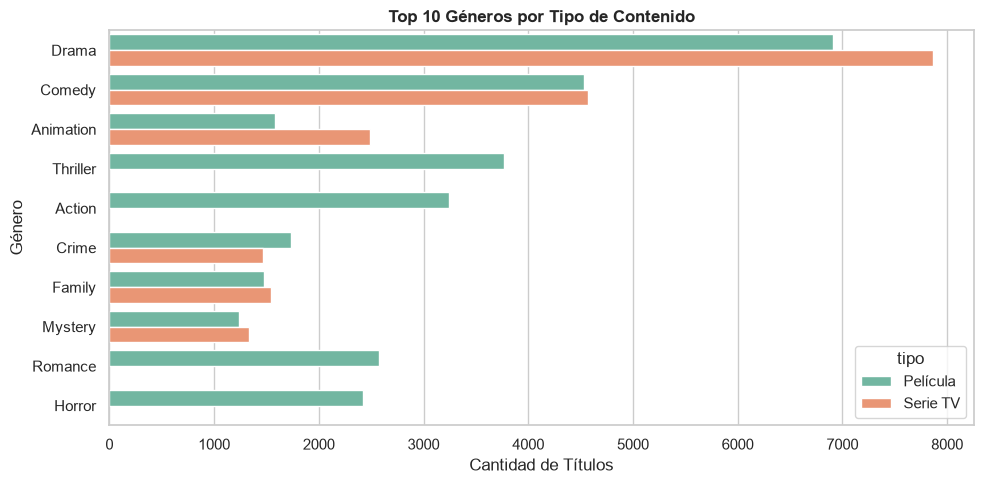

In [25]:
# Gráfico 1: Distribución del catálogo por género y tipo de contenido
df_m = df_movies_clean.copy()
df_t = df_tv_clean.copy()
df_m['tipo'] = 'Película'
df_t['tipo'] = 'Serie TV'

df_m_g = df_m.assign(genre_single=df_m['genres'].str.split(', ')).explode('genre_single')
df_t_g = df_t.assign(genre_single=df_t['genres'].str.split(', ')).explode('genre_single')

df_m_g['genre_single'] = df_m_g['genre_single'].str.strip()
df_t_g['genre_single'] = df_t_g['genre_single'].str.strip()

df_cat = pd.concat([df_m_g, df_t_g], ignore_index=True)
# Se excluyen los valores de relleno ('Sin Género') solo del RANKING, no del dataset limpio
df_cat_validos = df_cat[df_cat['genre_single'] != 'Sin Género']

top_genres = df_cat_validos['genre_single'].value_counts().head(10).index
df_cat_top = df_cat_validos[df_cat_validos['genre_single'].isin(top_genres)]

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
sns.countplot(data=df_cat_top, y='genre_single', hue='tipo', order=top_genres, palette='Set2')

plt.title('Top 10 Géneros por Tipo de Contenido', fontsize=12, fontweight='bold')
plt.xlabel('Cantidad de Títulos')
plt.ylabel('Género')
plt.tight_layout()
plt.show()


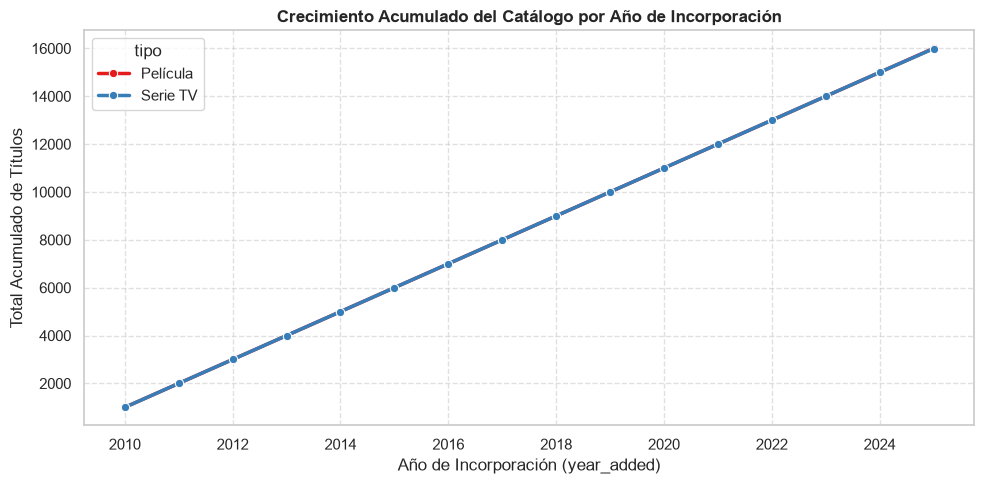

In [26]:
# Gráfico 2: Crecimiento acumulado del catálogo por año de incorporación
df_prod = pd.concat([
    df_movies_clean[['year_added']].assign(tipo='Película'),
    df_tv_clean[['year_added']].assign(tipo='Serie TV')
], ignore_index=True).dropna(subset=['year_added'])

prod_trend = df_prod.groupby(['year_added', 'tipo']).size().reset_index(name='count')
prod_trend['acumulado'] = prod_trend.groupby('tipo')['count'].cumsum()

plt.figure(figsize=(10, 5))
sns.lineplot(data=prod_trend, x='year_added', y='acumulado', hue='tipo', marker='o', palette='Set1', linewidth=2.5)

plt.title('Crecimiento Acumulado del Catálogo por Año de Incorporación', fontsize=12, fontweight='bold')
plt.xlabel('Año de Incorporación (year_added)')
plt.ylabel('Total Acumulado de Títulos')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


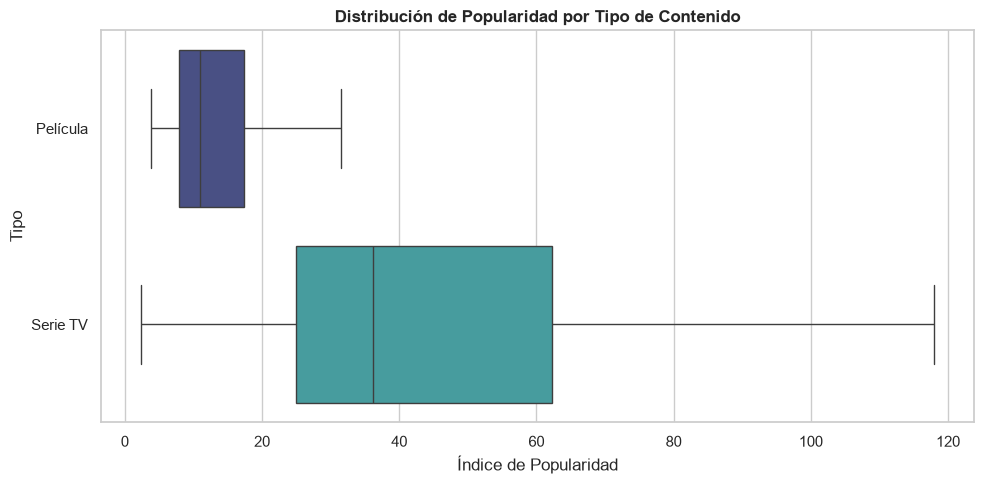

In [27]:
# Gráfico 3: Comparación de la distribución de popularidad entre Películas y Series
df_pop = pd.concat([
    df_movies_clean[['popularity']].assign(tipo='Película'),
    df_tv_clean[['popularity']].assign(tipo='Serie TV')
], ignore_index=True)

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
sns.boxplot(data=df_pop, x='popularity', y='tipo', hue='tipo', palette='mako', showfliers=False, legend=False)
plt.title('Distribución de Popularidad por Tipo de Contenido', fontsize=12, fontweight='bold')
plt.xlabel('Índice de Popularidad')
plt.ylabel('Tipo')
plt.tight_layout()
plt.show()


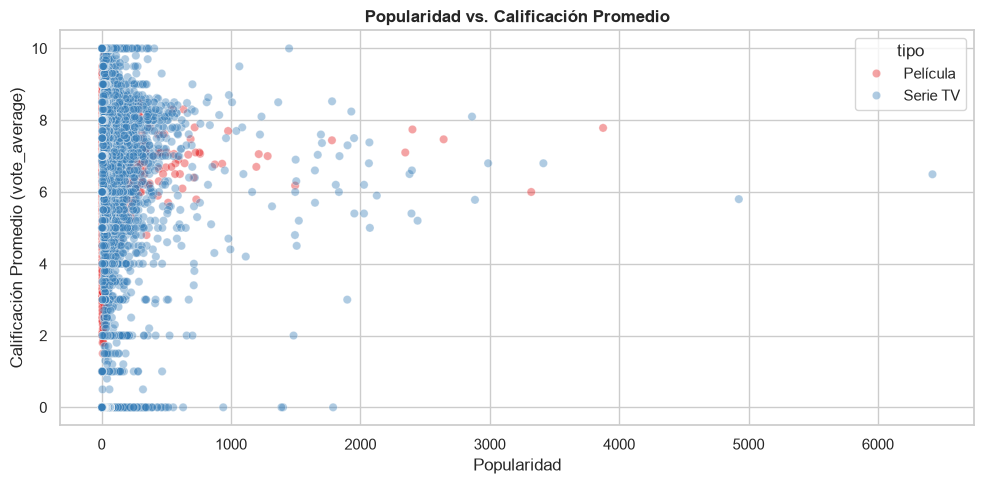

In [28]:
# Gráfico 4: Relación entre popularidad y calificación promedio
df_val = pd.concat([
    df_movies_clean[['popularity', 'vote_average']].assign(tipo='Película'),
    df_tv_clean[['popularity', 'vote_average']].assign(tipo='Serie TV')
], ignore_index=True)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_val, x='popularity', y='vote_average', hue='tipo', alpha=0.4, palette='Set1')
plt.title('Popularidad vs. Calificación Promedio', fontsize=12, fontweight='bold')
plt.xlabel('Popularidad')
plt.ylabel('Calificación Promedio (vote_average)')
plt.tight_layout()
plt.show()


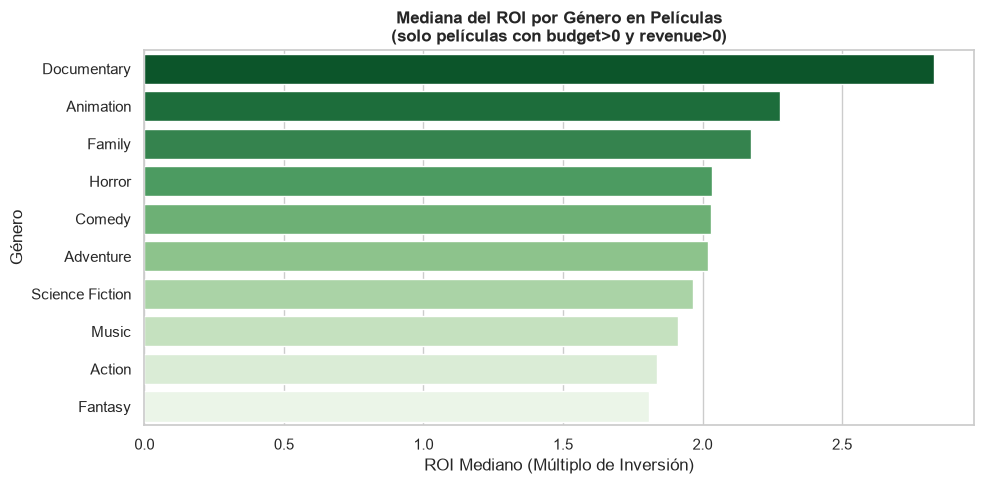

In [29]:
# Gráfico 5: Mediana de ROI por género (usando el ÚNICO subconjunto financiero definido antes: df_movies_financial)
df_m_g_roi = df_movies_financial.assign(
    genre_single=df_movies_financial['genres'].str.split(', ')
).explode('genre_single')
df_m_g_roi['genre_single'] = df_m_g_roi['genre_single'].str.strip()
df_m_g_roi = df_m_g_roi[df_m_g_roi['genre_single'] != 'Sin Género']

roi_by_genre = df_m_g_roi.groupby('genre_single')['roi'].median().nlargest(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=roi_by_genre, x='roi', y='genre_single', hue='genre_single', palette='Greens_r', legend=False)
plt.title('Mediana del ROI por Género en Películas\n(solo películas con budget>0 y revenue>0)', fontsize=12, fontweight='bold')
plt.xlabel('ROI Mediano (Múltiplo de Inversión)')
plt.ylabel('Género')
plt.tight_layout()
plt.show()


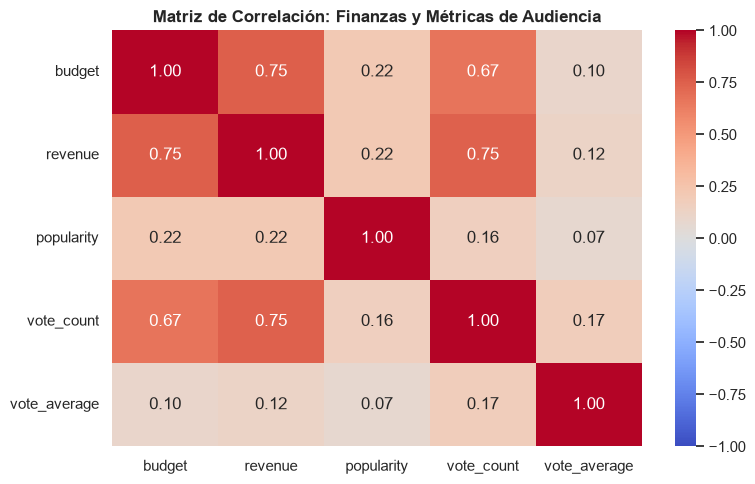

In [30]:
# Gráfico 6: Matriz de correlación entre variables cuantitativas (Películas, datos limpios)
cols_num = ['budget', 'revenue', 'popularity', 'vote_count', 'vote_average']
corr_matrix = df_movies_clean[cols_num].corr()

plt.figure(figsize=(8, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar=True)
plt.title('Matriz de Correlación: Finanzas y Métricas de Audiencia', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


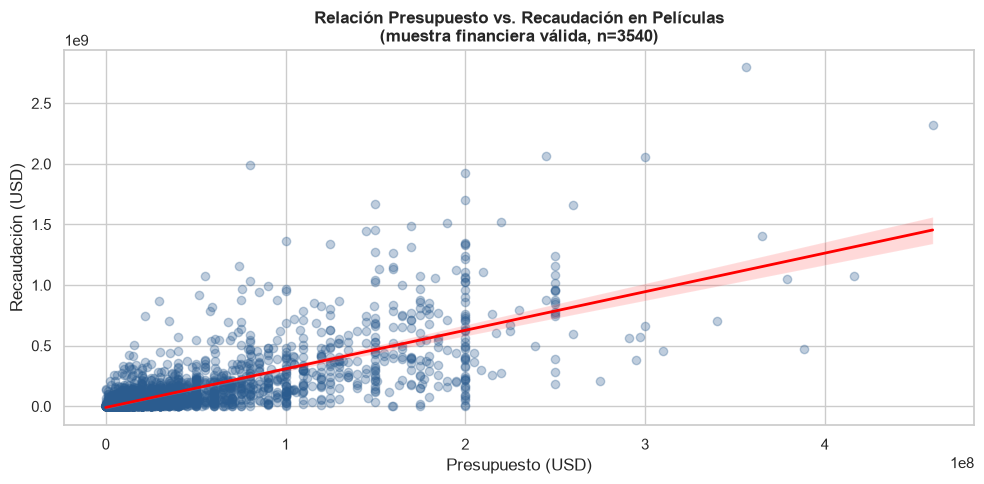

In [31]:
# Gráfico 7: Presupuesto vs Recaudación (usando el mismo subconjunto financiero df_movies_financial)
plt.figure(figsize=(10, 5))
sns.regplot(data=df_movies_financial, x='budget', y='revenue',
            scatter_kws={'alpha':0.3, 'color':'#2b5c8f'},
            line_kws={'color':'red', 'linewidth':2})
plt.title('Relación Presupuesto vs. Recaudación en Películas\n(muestra financiera válida, n=%d)' % len(df_movies_financial),
          fontsize=12, fontweight='bold')
plt.xlabel('Presupuesto (USD)')
plt.ylabel('Recaudación (USD)')
plt.tight_layout()
plt.show()


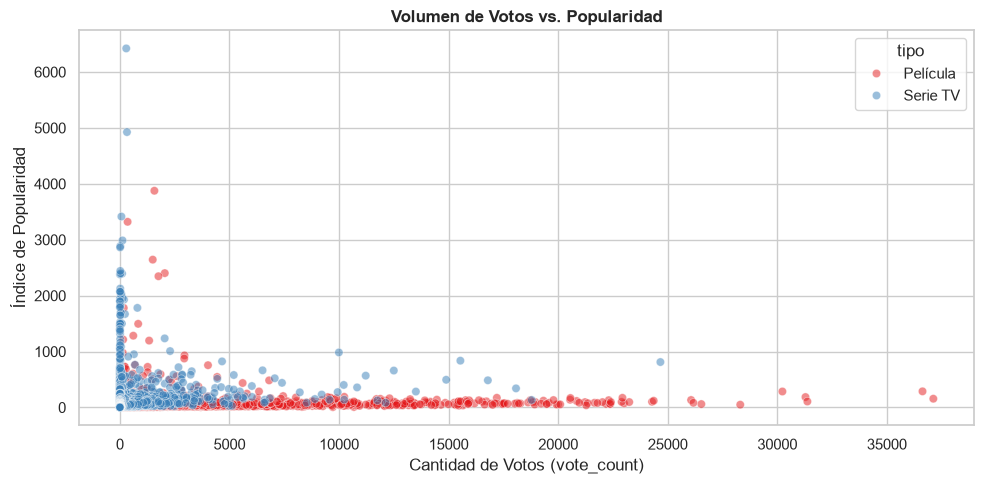

In [32]:
# Gráfico 8: Volumen de votos vs. popularidad
df_comb = pd.concat([
    df_movies_clean[['vote_count', 'popularity']].assign(tipo='Película'),
    df_tv_clean[['vote_count', 'popularity']].assign(tipo='Serie TV')
], ignore_index=True)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_comb, x='vote_count', y='popularity', hue='tipo', alpha=0.5, palette='Set1')
plt.title('Volumen de Votos vs. Popularidad', fontsize=12, fontweight='bold')
plt.xlabel('Cantidad de Votos (vote_count)')
plt.ylabel('Índice de Popularidad')
plt.tight_layout()
plt.show()


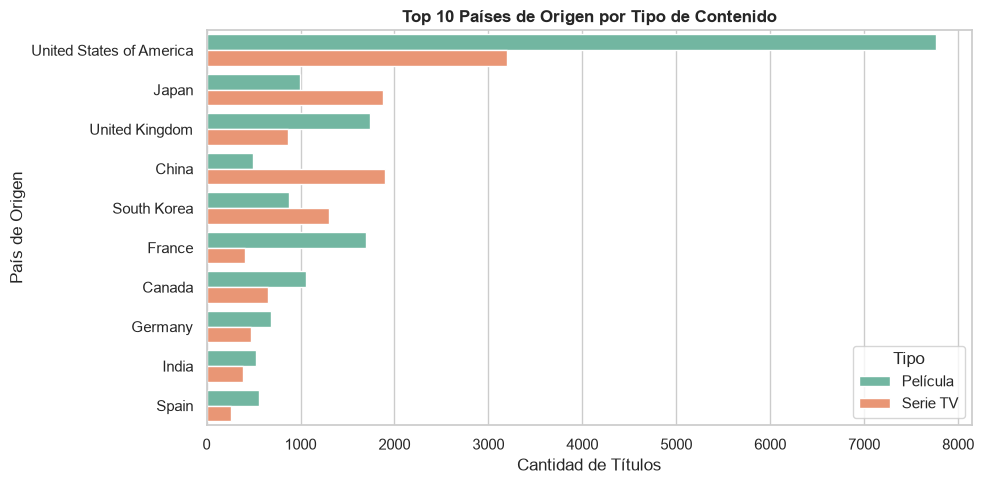

In [33]:
# Gráfico 9: Top 10 países de origen por tipo de contenido
df_m_c = df_movies_clean.assign(
    country_single=df_movies_clean['country'].str.split(', '), tipo='Película'
).explode('country_single')
df_t_c = df_tv_clean.assign(
    country_single=df_tv_clean['country'].str.split(', '), tipo='Serie TV'
).explode('country_single')

df_m_c['country_single'] = df_m_c['country_single'].str.strip()
df_t_c['country_single'] = df_t_c['country_single'].str.strip()

df_countries = pd.concat([df_m_c, df_t_c], ignore_index=True)
df_countries_validos = df_countries[df_countries['country_single'] != 'Sin Información']

top_10 = df_countries_validos['country_single'].value_counts().head(10).index
df_top_countries = df_countries_validos[df_countries_validos['country_single'].isin(top_10)]

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
sns.countplot(
    data=df_top_countries,
    y='country_single',
    hue='tipo',
    order=top_10,
    palette='Set2'
)

plt.title('Top 10 Países de Origen por Tipo de Contenido', fontsize=12, fontweight='bold')
plt.xlabel('Cantidad de Títulos')
plt.ylabel('País de Origen')
plt.legend(title='Tipo')
plt.tight_layout()
plt.show()


### Resumen de calidad de datos y variables no utilizables

Para dejar trazabilidad clara antes de pasar al informe/dashboard:

| Variable | Estado | Tratamiento |
|---|---|---|
| `duration` (Películas) | 100% nula (16.000/16.000) | Excluida del análisis de duración |
| `duration` / `seasons_count` (Series) | 100% constante ("1 Seasons") | Excluida del análisis; no aporta varianza |
| `director`, `cast`, `country`, `genres` | Nulos parciales (hasta 68,5% en `director` de Series) | Imputados con "Sin Información"/"Sin Género"; no se elimina ninguna fila |
| `budget`, `revenue` (Películas) | 69,7% / 64,7% en cero (dato faltante, no costo real) | Se usa el subconjunto `df_movies_financial` (budget>0 y revenue>0, 3.540 películas = 22,1% del catálogo de películas) para cualquier indicador financiero |
| ROI | Promedio distorsionado por outliers de presupuesto irrisorio | Se reporta la **mediana** como estadístico principal en todo el notebook |
| Duplicados (Series) | 18 filas (9 títulos) | Eliminados, se conserva la primera instancia |

Todos los gráficos de este notebook usan `df_movies_clean` / `df_tv_clean` (o el subconjunto "
`df_movies_financial` derivado de estos), nunca los dataframes originales sin procesar.


In [34]:
# Guarda el DataFrame de películas sin duplicados y con nulos imputados
df_movies_clean.to_csv("../CSV procesados/netflix_movies_clean.csv", index=False)

# Guarda el DataFrame de series de TV limpio y con el conteo de temporadas
df_tv_clean.to_csv("../CSV procesados/netflix_tv_clean.csv", index=False)

# Guarda el subconjunto de películas filtradas con la columna 'roi'
df_movies_financial.to_csv("../CSV procesados/netflix_movies_financial_clean.csv", index=False)